# Пилот серии r3: число повторов

**Задача.** Определить, сколько прогонов на каждый вариант нужно в кампании r3,
чтобы различать относительную разницу между вариантами заданной величины.

**Метод.** Предварительный эксперимент (пилот) измеряет разброс метрики между
прогонами; по нему рассчитывается объём выборки основной серии (Kalibera,
Jones, *Rigorous Benchmarking in Reasonable Time*, ISMM 2013). Поскольку
разброс оценивается по малой выборке, в расчёт берётся его верхняя
доверительная граница (Browne, 1995). Конфигурация пилота и правила расчёта
зафиксированы в `nir3-spec.md`, раздел 5, до съёмки.

| Параметр | Значение |
|---|---|
| Платформы | Mac (Apple M4) · Chromium 153; Windows (AMD Ryzen 5 3550H) · Firefox 155 |
| Сценарии | S1–S5, все варианты матрицы `nir3-spec.md`, раздел 2 |
| Прогонов на ячейку | 5 (S3 — 10) и один прогревочный, не сохраняемый |
| Данные | `results/<устройство>/<браузер>/<сценарий>/pilot <время>/` (формат — `docs/DATA.md`) |

Ноутбук воспроизводит расчёт целиком из сырых CSV пилота.

In [1]:
import json
import math
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import chi2, norm

RESULTS = Path.cwd().parent / "results"
CAMPAIGN = "pilot"

# Стиль графиков: приглушённые оси и сетка, цвет закреплён за платформой
INK, MUTED, GRID, SURFACE = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titlesize": 10,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "legend.frameon": False,
})
PLATFORM_COLOR = {"Mac · Chromium": "#2a78d6", "Windows · Firefox": "#eb6834"}
pd.set_option("display.max_rows", 200, "display.width", 160)

## 1. Данные пилота и их допуск

Серия допускается к расчёту, если она завершена (`finished`), снята на
закоммиченном коде (`code.clean`), прошла проверку паритета сцен и содержит
все запланированные прогоны.

In [2]:
PLATFORM = {("apple-m4", "chromium"): "Mac · Chromium", ("amd-ryzen-5-3550h", "firefox"): "Windows · Firefox"}

series = []
for path in sorted(RESULTS.glob(f"*/*/*/{CAMPAIGN} */manifest.json")):
    device, browser, scenario = path.relative_to(RESULTS).parts[:3]
    m = json.loads(path.read_text())
    cells = defaultdict(int)
    for r in m["runs"]:
        cells[(r["variant"], r.get("load", "-"))] += 1
    series.append({
        "платформа": PLATFORM[(device, browser)], "сценарий": scenario, "dir": path.parent, "manifest": m,
        "завершена": m["finished"] is not None, "код чистый": m["code"]["clean"], "коммит": m["code"]["commit"][:7],
        "паритет": m["parity"]["ok"], "ячеек": len(cells), "прогонов на ячейку": sorted(set(cells.values())),
        "сбоев": len(m["retries"]),
    })
S = pd.DataFrame(series)
S["допущена"] = S["завершена"] & S["код чистый"] & S["паритет"]
display(S.drop(columns=["dir", "manifest"]))
assert S["допущена"].all(), "в пилоте есть недопущенные серии"
display(Markdown(f"Допущено серий: **{S['допущена'].sum()} из {len(S)}**; коммит стенда: {', '.join(S['коммит'].unique())}."))

,платформа,сценарий,завершена,код чистый,коммит,паритет,ячеек,прогонов на ячейку,сбоев,допущена
0,Windows · Firefox,s1,True,True,3e2dfc2,True,6,[5],0,True
1,Windows · Firefox,s2,True,True,3e2dfc2,True,5,[5],0,True
2,Windows · Firefox,s3,True,True,3e2dfc2,True,2,[10],0,True
3,Windows · Firefox,s4,True,True,3e2dfc2,True,3,[5],0,True
4,Windows · Firefox,s5,True,True,3e2dfc2,True,2,[5],0,True
5,Mac · Chromium,s1,True,True,3e2dfc2,True,6,[5],0,True
6,Mac · Chromium,s2,True,True,3e2dfc2,True,5,[5],0,True
7,Mac · Chromium,s3,True,True,3e2dfc2,True,2,[10],0,True
8,Mac · Chromium,s4,True,True,3e2dfc2,True,3,[5],0,True
9,Mac · Chromium,s5,True,True,3e2dfc2,True,2,[5],0,True


Допущено серий: **10 из 10**; коммит стенда: 3e2dfc2.

## 2. Метрика прогона

Единица анализа — **прогон**: кадры и клики внутри прогона автокоррелированы и
независимыми наблюдениями не являются. Из каждого прогона берётся одно число.

| Сценарий | Метрика прогона | Роль | δ |
|---|---|---|---|
| S1, S2 | среднее время кадра, мс (= 1000 / FPS) | главная | 5% |
| S1, S2 | медиана и 99-й перцентиль времени кадра, мс | дополнительные | 5% / 10% |
| S3 | время до первого кадра (`render_end_ms`), мс | главная | 5% |
| S4 | медиана задержки «клик → отрисованный отклик» по попаданиям, мс | главная | 10% |
| S4 | 95-й перцентиль задержки, мс | дополнительная | 10% |
| S5 | ёмкость при 60 и при 30 FPS, объектов | главные | 5% |

δ — относительная разница между вариантами, которую должна различать
кампания (`nir3-spec.md`, раздел 5): 5% для центральных метрик и ёмкости,
10% для хвостов распределения и задержки ввода.

Почему главная метрика S1 и S2 — **среднее**, а не медиана времени кадра,
показано в разделе 4.2.

Ёмкость S5 — число объектов, при котором медианный FPS уровня опускается до
порога; между соседними уровнями свипа интерполируется линейно в
координатах (log N, log FPS).

In [3]:
def capacity(levels: dict[int, np.ndarray], fps: float) -> float:
    pts = sorted((n, 1000 / np.median(f)) for n, f in levels.items())
    for (na, fa), (nb, fb) in zip(pts, pts[1:]):
        if fa >= fps > fb:
            u = (math.log(fps) - math.log(fa)) / (math.log(fb) - math.log(fa))
            return math.exp(math.log(na) + u * (math.log(nb) - math.log(na)))
    return math.nan


def run_metrics(scenario: str, df: pd.DataFrame) -> dict[str, float]:
    if scenario in ("s1", "s2"):
        f = df["frame_ms"].to_numpy()
        return {"кадр, среднее": f.mean(), "кадр, медиана": np.median(f), "кадр, p99": np.percentile(f, 99)}
    if scenario == "s3":
        return {"время до первого кадра": df["render_end_ms"].iloc[0]}
    if scenario == "s4":
        ok = df[df["outcome"] == "ok"]
        lat = (ok["render_end_ms"] - ok["event_ms"]).to_numpy()
        return {"задержка, медиана": np.median(lat), "задержка, p95": np.percentile(lat, 95)}
    levels = {n: g["frame_ms"].to_numpy() for n, g in df.groupby("objects")}
    return {"ёмкость при 60 FPS": capacity(levels, 60), "ёмкость при 30 FPS": capacity(levels, 30)}


# метрика → (δ, главная ли)
METRIC = {
    "кадр, среднее": (0.05, True), "кадр, медиана": (0.05, False), "кадр, p99": (0.10, False),
    "время до первого кадра": (0.05, True),
    "задержка, медиана": (0.10, True), "задержка, p95": (0.10, False),
    "ёмкость при 60 FPS": (0.05, True), "ёмкость при 30 FPS": (0.05, True),
}

rows = []
for s in series:
    for r in s["manifest"]["runs"]:
        df = pd.read_csv(s["dir"] / r["file"])
        for metric, value in run_metrics(s["сценарий"], df).items():
            rows.append({"платформа": s["платформа"], "сценарий": s["сценарий"], "вариант": r["variant"],
                         "точка": r.get("load", "-"), "прогон": r["repeat"], "метрика": metric, "значение": value})
R = pd.DataFrame(rows)
display(Markdown(f"Значений метрик: {len(R)} (прогонов: {R.groupby(['платформа', 'сценарий', 'вариант', 'точка', 'прогон']).ngroups})."))

Значений метрик: 470 (прогонов: 200).

## 3. Разброс между прогонами

Разброс выражается стандартным отклонением **натурального логарифма**
метрики, *s*: для малых значений оно совпадает с коэффициентом вариации, а
отношения вариантов на логарифмической шкале становятся разностями.

На рисунке — главная метрика каждого прогона относительно среднего по своей
ячейке. Широкая полоса означает большой разброс между прогонами.

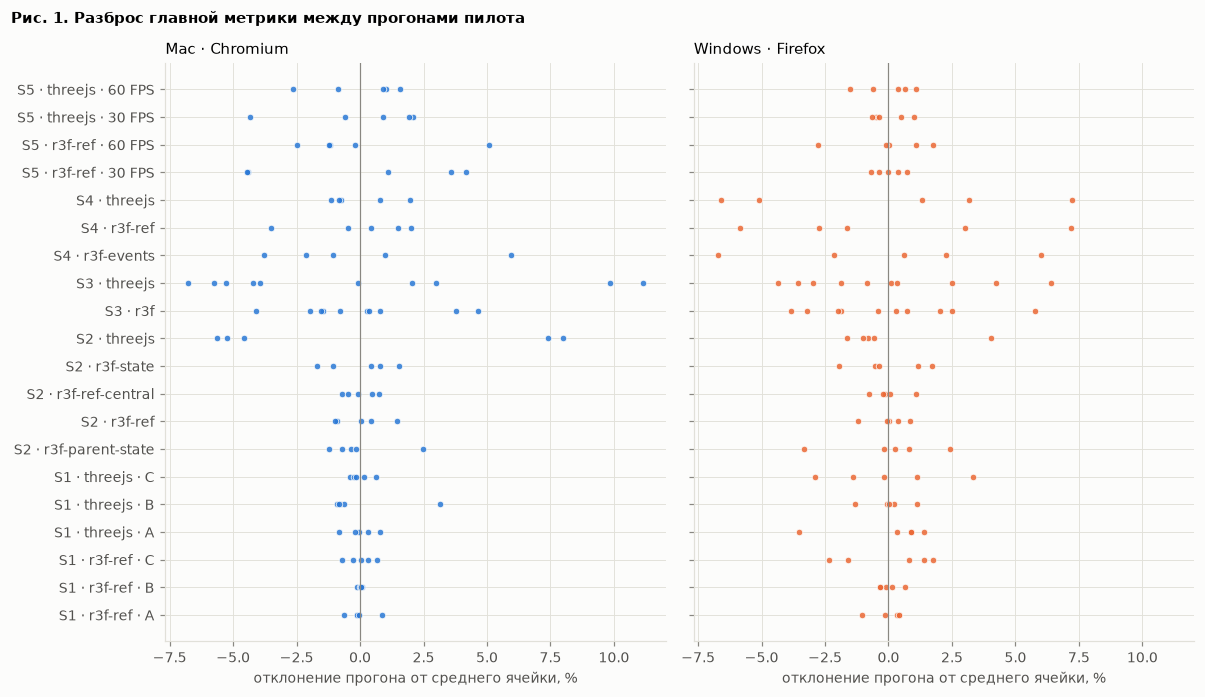

In [4]:
main = R[R["метрика"].map(lambda m: METRIC[m][1])].copy()
main["ячейка"] = main["сценарий"].str.upper() + " · " + main["вариант"] + main["точка"].map(lambda p: "" if p == "-" else f" · {p}") \
    + main["метрика"].map(lambda m: f" · {m.split()[-2]} {m.split()[-1]}" if m.startswith("ёмкость") else "")
main["отклонение, %"] = main.groupby(["платформа", "ячейка"])["значение"].transform(lambda v: (v / v.mean() - 1) * 100)

order = sorted(main["ячейка"].unique(), key=lambda c: (c[:2], c))
fig, axes = plt.subplots(1, 2, figsize=(11, 0.26 * len(order) + 1.2), sharex=True, sharey=True)
for ax, (platform, color) in zip(axes, PLATFORM_COLOR.items()):
    d = main[main["платформа"] == platform]
    y = {c: i for i, c in enumerate(order)}
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.scatter(d["отклонение, %"], d["ячейка"].map(y), s=18, color=color, alpha=0.85, edgecolor=SURFACE, linewidth=0.6)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set_title(platform)
    ax.set_xlabel("отклонение прогона от среднего ячейки, %")
fig.suptitle("Рис. 1. Разброс главной метрики между прогонами пилота", x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout()
plt.show()

Разброс большинства ячеек — единицы процентов. Выделяется одна ячейка:
**S2 · three.js на Mac · Chromium**, где значения разделены на две группы.
Она разобрана в разделе 4.

## 4. Ячейки, к которым модель разброса неприменима

Расчёт объёма выборки (раздел 5) предполагает, что значения прогонов
разбросаны вокруг одного уровня. Если значения ячейки образуют **два
устойчивых уровня**, увеличение числа прогонов разброс не уменьшает: оценка
*s* отражает расстояние между уровнями, а не шум.

**Критерий двух уровней.** Значения ячейки (в логарифмах) упорядочиваются и
делятся по наибольшему разрыву. Ячейка считается двухуровневой, если
одновременно:

- в каждой группе не меньше двух прогонов;
- разрыв больше чем в 4 раза превышает наибольшее стандартное отклонение
  внутри групп — группы отделены друг от друга;
- разрыв не меньше δ метрики — уровни различаются не меньше, чем эффект,
  который должна различать кампания. Более мелкие «ступеньки» при 5
  прогонах неотличимы от случайного расположения точек.

In [5]:
def two_levels(values: np.ndarray, delta: float) -> bool:
    x = np.sort(np.log(values))
    if len(x) < 4:
        return False
    i = int(np.argmax(np.diff(x)))
    lo, hi = x[: i + 1], x[i + 1:]
    if len(lo) < 2 or len(hi) < 2:
        return False
    within = max(np.std(lo, ddof=1), np.std(hi, ddof=1), 1e-4)
    gap = hi[0] - lo[-1]
    return gap > 4 * within and gap >= math.log1p(delta)


keys = ["платформа", "сценарий", "вариант", "точка", "метрика"]
flags = (R.groupby(keys)["значение"].apply(lambda v: two_levels(v.to_numpy(), METRIC[v.name[-1]][0]))
         .rename("два уровня").reset_index())
display(flags[flags["два уровня"]])

,платформа,сценарий,вариант,точка,метрика,два уровня
30,Mac · Chromium,s2,threejs,-,"кадр, p99",True
31,Mac · Chromium,s2,threejs,-,"кадр, медиана",True
32,Mac · Chromium,s2,threejs,-,"кадр, среднее",True


### 4.1. Mac · Chromium · S2 · three.js — два уровня быстродействия процесса

Уровень выбирается при старте процесса браузера и сохраняется весь прогон;
разница целиком приходится на фазу `render` — исполнение кода three.js на
CPU, — время GPU одинаково. Это явление разобрано на этапе 0
(`nir3-plan.md`, «Бимодальность на M4»): каждый новый процесс V8 получает
случайное состояние (фоновая JIT-компиляция, случайные зёрна, размещение
кода), что на M4 даёт два уровня быстродействия CPU-кода с разницей ≈ 7%.
Какой вариант затронет эффект — случайно; на AMD он не наблюдается.

Это реальный источник разброса, а не шум измерения. Его характеризуют
**доли прогонов на каждом уровне**, и для этого нужно достаточно прогонов
(раздел 6).

In [6]:
def frames_of(platform, scenario, variant):
    s = next(x for x in series if x["платформа"] == platform and x["сценарий"] == scenario)
    for r in s["manifest"]["runs"]:
        if r["variant"] == variant:
            yield r["repeat"], pd.read_csv(s["dir"] / r["file"])


t = []
for rep, df in frames_of("Mac · Chromium", "s2", "threejs"):
    half = len(df) // 2
    t.append({"прогон": rep, "кадр, среднее": df["frame_ms"].mean(), "update, медиана": df["update_ms"].median(),
              "render, медиана": df["render_ms"].median(), "GPU, медиана": df["gpu_ms"].median(),
              "кадр, 1-я половина": df["frame_ms"][:half].mean(), "кадр, 2-я половина": df["frame_ms"][half:].mean()})
display(pd.DataFrame(t).round(2))

,прогон,"кадр, среднее","update, медиана","render, медиана","GPU, медиана","кадр, 1-я половина","кадр, 2-я половина"
0,1,4.30,0.45,3.78,1.19,4.30,4.29
1,2,4.86,0.34,4.43,1.12,4.86,4.86
2,3,4.25,0.44,3.74,1.20,4.24,4.25
3,4,4.27,0.44,3.76,1.20,4.27,4.26
4,5,4.83,0.39,4.36,1.11,4.84,4.83


### 4.2. Windows · Firefox · S2 · state — чередование кадров и неустойчивость медианы

В варианте state (setState каждый кадр) в Firefox кадры **чередуются**:
половина кадров ≈ 18 мс, половина ≈ 66 мс (рис. 2) — по-видимому, работа
React по обновлению состояния выполняется через кадр (механизм не
установлен). Медиана распределения из двух равных по доле пиков не
определена устойчиво: она попадает в любую точку между пиками, и медиана
прогона «прыгает» между ≈ 44 и ≈ 63 мс. Среднее время кадра от этого не
зависит и стабильно.

,прогон,"кадр, медиана","кадр, среднее",доля кадров < 30 мс,"короткие, медиана","длинные, медиана"
0,1,43.640000,42.920000,50%,17.460000,65.770000
1,2,44.730000,44.300000,50%,18.380000,66.020000
2,3,45.490000,44.530000,50%,18.560000,67.300000
3,4,43.760000,43.540000,50%,17.640000,66.260000
4,5,62.680000,43.620000,50%,18.200000,64.400000


Разброс между прогонами: по медиане **15.5%**, по среднему **1.5%**.

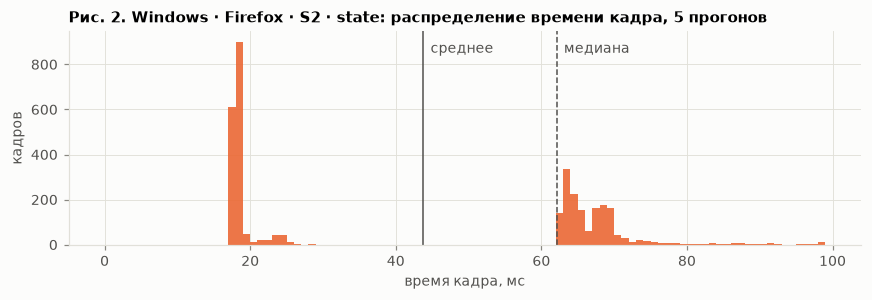

In [7]:
t, frames = [], []
for rep, df in frames_of("Windows · Firefox", "s2", "r3f-state"):
    f = df["frame_ms"].to_numpy()
    frames.append(f)
    t.append({"прогон": rep, "кадр, медиана": np.median(f), "кадр, среднее": f.mean(),
              "доля кадров < 30 мс": (f < 30).mean(), "короткие, медиана": np.median(f[f < 30]),
              "длинные, медиана": np.median(f[f >= 30])})
T = pd.DataFrame(t)
display(T.round(2).style.format({"доля кадров < 30 мс": "{:.0%}"}))
cv = lambda v: np.std(np.log(v), ddof=1) * 100
display(Markdown(f"Разброс между прогонами: по медиане **{cv(T['кадр, медиана']):.1f}%**, по среднему **{cv(T['кадр, среднее']):.1f}%**."))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(np.concatenate(frames), bins=np.arange(0, 100, 1), color=PLATFORM_COLOR["Windows · Firefox"], alpha=0.9)
for x, label, ls in [(T["кадр, среднее"].mean(), "среднее", "-"), (np.median(np.concatenate(frames)), "медиана", "--")]:
    ax.axvline(x, color=INK, lw=1, ls=ls)
    ax.text(x + 1, ax.get_ylim()[1] * 0.9, label, color=INK)
ax.set_xlabel("время кадра, мс")
ax.set_ylabel("кадров")
ax.set_title("Рис. 2. Windows · Firefox · S2 · state: распределение времени кадра, 5 прогонов", fontweight="bold")
fig.tight_layout()
plt.show()

**Решение (2026-10-15).** Главная метрика S1 и S2 — **среднее время
кадра** (оно же 1000 / FPS, пропускная способность); медиана сохраняется как
дополнительная. Изменение внесено в `nir3-spec.md`, раздел 3, до кампании.
С этой метрикой ячейка Firefox · state двух уровней не образует (критерий
раздела 4 её не отмечает).

## 5. Объём выборки

Для каждой ячейки по *k* прогонам пилота вычисляется *s* и его верхняя
односторонняя 80%-ная доверительная граница (Browne, 1995):

$$ s_{\uparrow} = s\,\sqrt{\frac{k-1}{\chi^2_{0{,}2;\,k-1}}} $$

По ней — число прогонов на вариант, достаточное, чтобы различить
относительную разницу δ между двумя вариантами при α = 0,05 (двусторонний
критерий) и мощности 0,8:

$$ n = \frac{2\,(z_{0{,}975} + z_{0{,}8})^2\, s_{\uparrow}^2}{\ln^2(1+\delta)} $$

Это та же формула, что в пилоте r2, дополненная поправкой на неточность
оценки разброса. При *k* = 5 поправка увеличивает *s* в 1,56 раза, при
*k* = 10 — в 1,29 раза.

In [8]:
ALPHA, POWER, UCL = 0.05, 0.80, 0.80
Z = norm.ppf(1 - ALPHA / 2) + norm.ppf(POWER)


def sample_size(values: np.ndarray, delta: float) -> pd.Series:
    x = np.log(values)
    k = len(x)
    s = np.std(x, ddof=1)
    s_up = s * math.sqrt((k - 1) / chi2.ppf(1 - UCL, k - 1))
    n = math.ceil(2 * Z**2 * s_up**2 / math.log1p(delta) ** 2)
    return pd.Series({"k": k, "s, %": s * 100, "s↑, %": s_up * 100, "δ": delta, "n": n})


N = R.groupby(keys)["значение"].apply(lambda v: sample_size(v.to_numpy(), METRIC[v.name[-1]][0])).unstack().reset_index()
N["главная"] = N["метрика"].map(lambda m: METRIC[m][1])
N = N.merge(flags, on=keys)
N["k"] = N["k"].astype(int)
N["n"] = N["n"].astype(int)
display(N[N["главная"]].drop(columns="главная").round(2).sort_values(["сценарий", "платформа", "вариант", "точка"]))

,платформа,сценарий,вариант,точка,метрика,k,"s, %","s↑, %",δ,n,два уровня
2,Mac · Chromium,s1,r3f-ref,A,"кадр, среднее",5,0.54,0.85,0.05,1,False
5,Mac · Chromium,s1,r3f-ref,B,"кадр, среднее",5,0.08,0.12,0.05,1,False
8,Mac · Chromium,s1,r3f-ref,C,"кадр, среднее",5,0.54,0.84,0.05,1,False
11,Mac · Chromium,s1,threejs,A,"кадр, среднее",5,0.60,0.93,0.05,1,False
14,Mac · Chromium,s1,threejs,B,"кадр, среднее",5,1.75,2.72,0.05,5,False
17,Mac · Chromium,s1,threejs,C,"кадр, среднее",5,0.41,0.64,0.05,1,False
47,Windows · Firefox,s1,r3f-ref,A,"кадр, среднее",5,0.63,0.99,0.05,1,False
50,Windows · Firefox,s1,r3f-ref,B,"кадр, среднее",5,0.41,0.64,0.05,1,False
53,Windows · Firefox,s1,r3f-ref,C,"кадр, среднее",5,1.85,2.89,0.05,6,False
56,Windows · Firefox,s1,threejs,A,"кадр, среднее",5,2.04,3.18,0.05,7,False


Дополнительные метрики — для сведения. Хвосты распределения (p99, p95) по
5 прогонам оцениваются грубо, поэтому объём выборки по ним не выбирается.

In [9]:
display(N[~N["главная"]].groupby(["сценарий", "метрика"])["n"].agg(["median", "max"]).rename(columns={"median": "n, медиана по ячейкам", "max": "n, максимум"}))

n, медиана по ячейкам  n, максимум
сценарий метрика                                          
s1       кадр, p99                        2.0           35
         кадр, медиана                    1.5            4
s2       кадр, p99                        3.0           32
         кадр, медиана                    4.0          386
s4       задержка, p95                    3.5            7

## 6. Правила выбора и итог

1. **Расчёт.** По сценарию берётся максимум *n* по главным метрикам всех
   ячеек обеих платформ, кроме двухуровневых.
2. **Нижняя граница — 10 прогонов.** Формула раздела 5 опирается на
   нормальное приближение и при малых *n* занижает требуемый объём; кроме
   того, бутстреп-интервалы, которыми пользуется анализ, при выборках меньше
   ≈ 10 не обеспечивают номинального покрытия.
3. **Двухуровневые ячейки — 30 прогонов.** Для них оценивается доля
   прогонов на каждом уровне; при 30 прогонах полуширина 95%-ного интервала
   доли не превышает ±0,18 (1,96·√(0,25/30)), и на каждом уровне оказывается
   достаточно прогонов, чтобы оценить его положение.

In [10]:
MIN_N, TWO_LEVEL_N = 10, 30

m = N[N["главная"]]
rows = []
for scenario, g in m.groupby("сценарий"):
    regular = g[~g["два уровня"]]
    worst = regular.loc[regular["n"].idxmax()]
    n_calc = int(worst["n"])
    two = bool(g["два уровня"].any())
    n_final = max(n_calc, MIN_N, TWO_LEVEL_N if two else 0)
    rule = "двухуровневая ячейка" if two and n_final == TWO_LEVEL_N else "нижняя граница" if n_final == MIN_N and n_calc < MIN_N else "расчёт"
    rows.append({"сценарий": scenario, "n по расчёту": n_calc,
                 "определяет": f"{worst['платформа']} · {worst['вариант']}{'' if worst['точка'] == '-' else ' · ' + worst['точка']} · {worst['метрика']}",
                 "двухуровневые ячейки": "есть" if two else "нет", "n для кампании": n_final, "правило": rule})
RESULT = pd.DataFrame(rows).set_index("сценарий")
display(RESULT)
REPEATS = RESULT["n для кампании"].to_dict()
print("SCENARIO_DEFAULTS.repeats =", REPEATS)

,n по расчёту,определяет,двухуровневые ячейки,n для кампании,правило
сценарий,,,,,
s1,9,"Windows · Firefox · threejs · C · кадр, среднее",нет,10,нижняя граница
s2,9,"Windows · Firefox · threejs · кадр, среднее",есть,30,двухуровневая ячейка
s3,45,Mac · Chromium · threejs · время до первого кадра,нет,45,расчёт
s4,15,"Windows · Firefox · threejs · задержка, медиана",нет,15,расчёт
s5,29,Mac · Chromium · r3f-ref · ёмкость при 30 FPS,нет,29,расчёт


SCENARIO_DEFAULTS.repeats = {'s1': 10, 's2': 30, 's3': 45, 's4': 15, 's5': 29}


## 7. Сверка с кампанией r2

Пилот сравнивается с кампанией r2 на тех же машинах (10–30 прогонов на
ячейку, стенд до перестройки). Метрики r2 взяты из итогов прогонов r2
(`frame_ms_mean`, `ttfr_submit_ms`, `latency_render_ms_median`,
`capacity_fps60/30`); определения совпадают с разделом 2.

Оценка разброса по 5 прогонам сама по себе неточна: 95%-ный доверительный
интервал *s* при *k* = 5 — от 0,60 *s* до 2,87 *s*. Поэтому разброс r2
сравнивается не «на глаз», а с этим интервалом:

- **внутри интервала** — пилот и r2 согласуются;
- **выше s↑** (верхней границы, по которой считалось *n*) — пилот, возможно,
  недооценил разброс, и *n* для этой ячейки может оказаться мало. Такие
  ячейки разбираются до кампании (`nir3-spec.md`, раздел 5).

Данные r2 удаляются из `results/` после кампании r3; тогда раздел
пропускается.

In [11]:
R2_SOURCES = {
    "Mac · Chromium": "apple-m4/chromium",
    "Windows · Firefox": "amd-ryzen-5-3550h-with-radeon-vega-mobile-gfx/firefox",
}
R2_METRIC = {"frame_ms_mean": "кадр, среднее", "ttfr_submit_ms": "время до первого кадра",
             "latency_render_ms_median": "задержка, медиана", "capacity_fps60": "ёмкость при 60 FPS",
             "capacity_fps30": "ёмкость при 30 FPS"}
R2_VARIANT = {"r3f-ref+parent-state": "r3f-parent-state"}

r2 = []
for platform, prefix in R2_SOURCES.items():
    for path in sorted(RESULTS.glob(f"{prefix}/*/r2 */manifest.json")):
        m = json.loads(path.read_text())
        c = m["config"]
        if c.get("trace") or c.get("cpuThrottle", 1) != 1 or c.get("network", "none") != "none":
            continue
        for run in m["runs"]:
            if run["warmup"] or run.get("control"):
                continue
            res = json.loads((path.parent / run["file"]).read_text())["result"]
            src = res.get("summary", {}) | {k: res.get(k) for k in ("ttfr_submit_ms", "capacity_fps60", "capacity_fps30")}
            for key, metric in R2_METRIC.items():
                v = src.get(key)
                if isinstance(v, (int, float)) and v > 0:
                    r2.append({"платформа": platform, "сценарий": c["scenario"], "вариант": R2_VARIANT.get(run["label"], run["label"]),
                               "точка": run.get("load") or "-", "метрика": metric, "значение": v})
if not r2:
    display(Markdown("Данных r2 в `results/` нет — сверка пропущена."))
else:
    R2 = pd.DataFrame(r2)
    cv = lambda v: np.std(np.log(v), ddof=1) * 100
    a = R2.groupby(keys)["значение"].agg([cv, "size"]).set_axis(["s r2, %", "k r2"], axis=1)
    b = N.set_index(keys)[["k", "s, %", "s↑, %", "два уровня"]].rename(columns={"k": "k пилот", "s, %": "s пилот, %"})
    cmp = b.join(a, how="inner")
    k = cmp["k пилот"]
    cmp["95% ДИ s пилота, %"] = [f"{s * math.sqrt((n - 1) / chi2.ppf(0.975, n - 1)):.2f}–{s * math.sqrt((n - 1) / chi2.ppf(0.025, n - 1)):.2f}"
                                  for s, n in zip(cmp["s пилот, %"], k)]
    lo = cmp["s пилот, %"] * np.sqrt((k - 1) / chi2.ppf(0.975, k - 1))
    hi = cmp["s пилот, %"] * np.sqrt((k - 1) / chi2.ppf(0.025, k - 1))
    cmp["r2 относительно пилота"] = np.where(cmp["s r2, %"] > cmp["s↑, %"], "выше s↑",
                                     np.where((cmp["s r2, %"] >= lo) & (cmp["s r2, %"] <= hi), "в интервале", "ниже интервала"))
    display(cmp.round(2))
    counts = cmp["r2 относительно пилота"].value_counts()
    display(Markdown(f"Ячеек в сверке: {len(cmp)}. " + "; ".join(f"{k}: {v}" for k, v in counts.items()) + "."))
    above = cmp[cmp["r2 относительно пилота"] == "выше s↑"]
    if len(above):
        above = above.join(N.set_index(keys)["δ"])
        above["n по разбросу r2"] = [math.ceil(2 * Z**2 * (s / 100) ** 2 / math.log1p(d) ** 2) for s, d in zip(above["s r2, %"], above["δ"])]
        above["n для кампании"] = [REPEATS[i[1]] for i in above.index]
        display(Markdown("Ячейки, где разброс r2 выше s↑: хватает ли выбранного *n*, если верен разброс r2."))
        display(above[["s пилот, %", "s↑, %", "s r2, %", "n по разбросу r2", "n для кампании"]].round(2))
        enough = (above["n по разбросу r2"] <= above["n для кампании"]).all()
        display(Markdown("**Итог сверки:** " + ("во всех ячейках, где r2 шумнее оценки пилота, выбранного *n* хватает и при разбросе r2."
                                                 if enough else "в части ячеек выбранного *n* при разбросе r2 не хватает — разобрать до кампании.")))

k пилот  s пилот, %  s↑, %  два уровня  s r2, %  k r2 95% ДИ s пилота, %  \
платформа         сценарий вариант          точка метрика                                                                                            
Mac · Chromium    s1       r3f-ref          A     кадр, среднее                 5        0.54   0.85       False     0.51    10          0.33–1.56   
                                            B     кадр, среднее                 5        0.08   0.12       False     0.24    10          0.05–0.22   
                                            C     кадр, среднее                 5        0.54   0.84       False     0.69    10          0.32–1.54   
                           threejs          A     кадр, среднее                 5        0.60   0.93       False     0.35    10          0.36–1.72   
                                            B     кадр, среднее                 5        1.75   2.72       False     0.13    10          1.05–5.02   
                                            C     кадр, среднее                 5        0.41   0.64       False     0.80    10          0.24–1.17   
                  s2       r3f-parent-state -     кадр, среднее                 5        1.43   2.23       False     1.60    30          0.86–4.11   
                           r3f-ref          -     кадр, среднее                 5        1.02   1.58       False     0.47    30          0.61–2.92   
                           r3f-ref-central  -     кадр, среднее                 5        0.62   0.97       False     1.91    30          0.37–1.78   
                           r3f-state        -     кадр, среднее                 5        1.34   2.08       False     0.55    30          0.80–3.84   
                           threejs          -     кадр, среднее                 5        6.97  10.86        True     5.08    30         4.18–20.03   
                  s3       r3f              -     время до первого кадра       10        2.62   3.39       False     2.57    30          1.80–4.78   
                           threejs          -     время до первого кадра       10        6.33   8.19       False     4.80    30         4.36–11.56   
                  s4       r3f-events       -     задержка, медиана             5        3.70   5.77       False     4.45    20         2.22–10.64   
                           r3f-ref          -     задержка, медиана             5        2.19   3.42       False     4.97    20          1.31–6.30   
                           threejs          -     задержка, медиана             5        1.33   2.07       False     3.94    20          0.80–3.82   
                  s5       r3f-ref          -     ёмкость при 30 FPS            5        4.23   6.59       False     4.44     8         2.54–12.16   
                                                  ёмкость при 60 FPS            5        2.90   4.51       False     3.59     8          1.74–8.33   
                           threejs          -     ёмкость при 30 FPS            5        2.67   4.16       False     2.64     8          1.60–7.67   
                                                  ёмкость при 60 FPS            5        1.76   2.74       False     2.61     8          1.05–5.05   
Windows · Firefox s1       r3f-ref          A     кадр, среднее                 5        0.63   0.99       False     0.26    10          0.38–1.82   
                                            B     кадр, среднее                 5        0.41   0.64       False     1.07    10          0.24–1.17   
                                            C     кадр, среднее                 5        1.85   2.89       False     1.86    10          1.11–5.33   
                           threejs          A     кадр, среднее                 5        2.04   3.18       False     0.22    10          1.22–5.87   
                                            B     кадр, среднее                 5        0.88   1.37       False     0.77    10          0.53–2.52   
                        

Ячеек в сверке: 40. в интервале: 22; выше s↑: 10; ниже интервала: 8.

Ячейки, где разброс r2 выше s↑: хватает ли выбранного *n*, если верен разброс r2.

s пилот, %  s↑, %  s r2, %  n по разбросу r2  n для кампании
платформа         сценарий вариант         точка метрика                                                                             
Mac · Chromium    s1       r3f-ref         B     кадр, среднее                 0.08   0.12     0.24                 1              10
                           threejs         C     кадр, среднее                 0.41   0.64     0.80                 1              10
                  s2       r3f-ref-central -     кадр, среднее                 0.62   0.97     1.91                 3              30
                  s4       r3f-ref         -     задержка, медиана             2.19   3.42     4.97                 5              15
                           threejs         -     задержка, медиана             1.33   2.07     3.94                 3              15
Windows · Firefox s1       r3f-ref         B     кадр, среднее                 0.41   0.64     1.07                 1              10
                  s2       r3f-ref         -     кадр, среднее                 0.77   1.20     1.21                 1              30
                  s3       threejs         -     время до первого кадра        3.46   4.48     4.59                14              45
                  s5       r3f-ref         -     ёмкость при 30 FPS            0.57   0.88     1.39                 2              29
                           threejs         -     ёмкость при 30 FPS            0.71   1.10     1.19                 1              29

**Итог сверки:** во всех ячейках, где r2 шумнее оценки пилота, выбранного *n* хватает и при разбросе r2.

## 8. Длительность кампании r3

Длительность прогона почти не зависит от варианта: окна прогрева и записи
фиксированы. Время на прогон оценивается по сериям пилота
(`finished − created`, делённое на число выполненных прогонов, включая
прогревочные и проверку паритета) и умножается на план кампании:
ячеек × (n + 1 прогревочный). Firefox на Mac в пилоте не снимался — для него
взяты времена Windows · Firefox (оценка сверху: Windows-машина медленнее).
WebKit — по временам Mac · Chromium.

In [12]:
def stamp(s: str) -> datetime:
    return datetime.fromisoformat(s.replace("Z", "+00:00"))


per_run = {}
for s in series:
    m = s["manifest"]
    executed = len(m["runs"]) + s["ячеек"]  # + по одному прогревочному на ячейку
    per_run[(s["платформа"], s["сценарий"])] = (stamp(m["finished"]) - stamp(m["created"])).total_seconds() / executed

CELLS = {"s1": 6, "s2": 5, "s3": 2, "s4": 3, "s5": 2}
PLAN = {
    "Mac": [("Chromium", "Mac · Chromium", "s1 s2 s3 s4 s5"), ("Firefox", "Windows · Firefox", "s1 s2 s3 s4 s5"),
            ("WebKit", "Mac · Chromium", "s2 s3 s4")],
    "Windows": [("Chromium", "Mac · Chromium", "s1 s2 s3 s4 s5"), ("Firefox", "Windows · Firefox", "s1 s2 s3 s4 s5")],
}
rows = []
for device, browsers in PLAN.items():
    for browser, source, scenarios in browsers:
        for sc in scenarios.split():
            rows.append({"устройство": device, "браузер": browser, "сценарий": sc,
                         "часов": per_run[(source, sc)] * CELLS[sc] * (REPEATS[sc] + 1) / 3600})
D = pd.DataFrame(rows)
display(D.pivot_table(index=["устройство", "браузер"], columns="сценарий", values="часов", aggfunc="sum", margins=True, margins_name="всего").round(1))

сценарий              s1   s2   s3   s4   s5  всего
устройство браузер                                 
Mac        Chromium  0.7  1.7  0.1  0.5  1.7    4.7
           Firefox   0.8  1.8  0.1  0.5  1.4    4.6
           WebKit    NaN  1.7  0.1  0.5  NaN    2.3
Windows    Chromium  0.7  1.7  0.1  0.5  1.7    4.7
           Firefox   0.8  1.8  0.1  0.5  1.4    4.6
всего                3.0  8.6  0.6  2.7  6.1   21.0

## Выводы

Таблица раздела 6 — число прогонов на вариант для кампании r3; оно
переносится в `packages/harness/src/config.ts` (`SCENARIO_DEFAULTS`, поле
`repeats`) и в `nir3-spec.md` одним коммитом, с которого снимается вся
кампания.

- Разброс между прогонами в пилоте — от долей процента до единиц
  процентов. С r2 он согласуется: где r2 шумнее верхней оценки пилота,
  выбранного числа прогонов хватает и при разбросе r2 (раздел 7).
- Единственная двухуровневая ячейка — S2 · three.js на Mac · Chromium:
  случайное состояние процесса V8 (этап 0). Она задаёт 30 прогонов для S2;
  в анализе такие ячейки описываются уровнями и долями, а не одним числом.
- Вариант state в Firefox даёт чередование коротких и длинных кадров; медиана
  кадра для него неустойчива, поэтому главная метрика S1 и S2 — среднее время
  кадра.